# Three-site eigenvalues and paper comparisons

Reproduce the numerical references for Eqs. (9–12), Figs. 3–4, and Sec. V B. The saved coefficients below are the published, rounded Eq. (12), not a reconstructed original checkpoint. A complete fresh training command appears at the end.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from experiments.paper import ROOT
print('Repository:', ROOT)

Repository: /home/al/Documents/MNRKAN/NMRKan


In [2]:
from experiments.paper import (exact_three, perturbation_three, published_predictions,
                              grid_three, basis, make_dataset, metrics)
local = grid_three(.2, 101)
local_error = metrics(perturbation_three(local), exact_three(local))
print('Local second-order perturbation:', local_error)
assert abs(local_error['rmse'] - 4.28e-5) < 5e-8
assert abs(local_error['max_abs_error'] - 2.64e-4) < 5e-7

Local second-order perturbation: {'rmse': 4.2826008096523146e-05, 'max_abs_error': 0.0002637712905788625, 'r2_per_branch': [0.9999970904868813, 0.9999953281628386, 0.999993113989108, 0.99999579126143]}


The leading ordered splitting is radial in $(r_1,r_2)$, and is nonanalytic at the origin. The ratios containing $1/(r_1^2+r_2^2)$ are assigned their continuous limit of zero there. Along the uniform line the signed perturbative branches cross; the energy-ordered spectrum has a cusp.

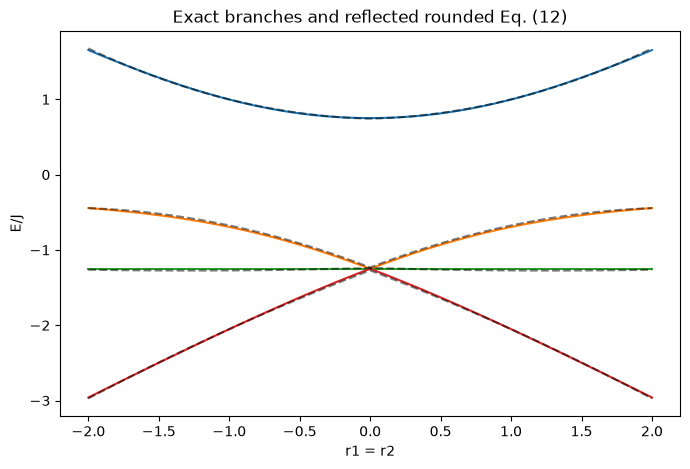

In [3]:
r = np.linspace(-2, 2, 401)
x = np.column_stack((r,r))
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(r, exact_three(x))
ax.plot(r, published_predictions(abs(x)), 'k--', alpha=.5)
ax.set(xlabel='r1 = r2', ylabel='E/J', title='Exact branches and reflected rounded Eq. (12)')
plt.show()

## Global and local errors
Use the original notebook's NumPy seed and separate coordinate draws. OLS validation coefficients are fitted on the training subset; the complete-sample fit is separately labeled. Globally fitted models are evaluated on the small local grid without refitting.

In [4]:
config = json.loads((ROOT/'configs/paper/three_site.json').read_text())
x, y, train, validation = make_dataset(config)
quadratic = basis(x); radial = basis(x, True)
quad_coeff = np.linalg.lstsq(quadratic[train], y[train], rcond=None)[0]
radial_coeff = np.linalg.lstsq(radial[train], y[train], rcond=None)[0]
full_coeff = np.linalg.lstsq(quadratic, y, rcond=None)[0]
global_grid = grid_three()
comparisons = {
    'OLS quadratic, held-out': metrics(quadratic[validation]@quad_coeff, y[validation]),
    'OLS radial, held-out': metrics(radial[validation]@radial_coeff, y[validation]),
    'OLS quadratic, complete-sample fit': metrics(quadratic@full_coeff, y),
    'OLS quadratic, local grid': metrics(basis(local)@quad_coeff, exact_three(local)),
    'OLS radial, local grid': metrics(basis(local, True)@radial_coeff, exact_three(local)),
    'Perturbation, local grid': local_error,
    'Rounded Eq. (12), 121x121 grid': metrics(published_predictions(global_grid), exact_three(global_grid)),
}
pd.DataFrame(comparisons).T[['rmse','max_abs_error']]

,rmse,max_abs_error
"OLS quadratic, held-out",0.016095,0.110563
"OLS radial, held-out",0.01402,0.118506
"OLS quadratic, complete-sample fit",0.016131,0.110958
"OLS quadratic, local grid",0.017189,0.03319
"OLS radial, local grid",0.00652,0.015964
"Perturbation, local grid",0.000043,0.000264
"Rounded Eq. (12), 121x121 grid",0.019035,0.162786


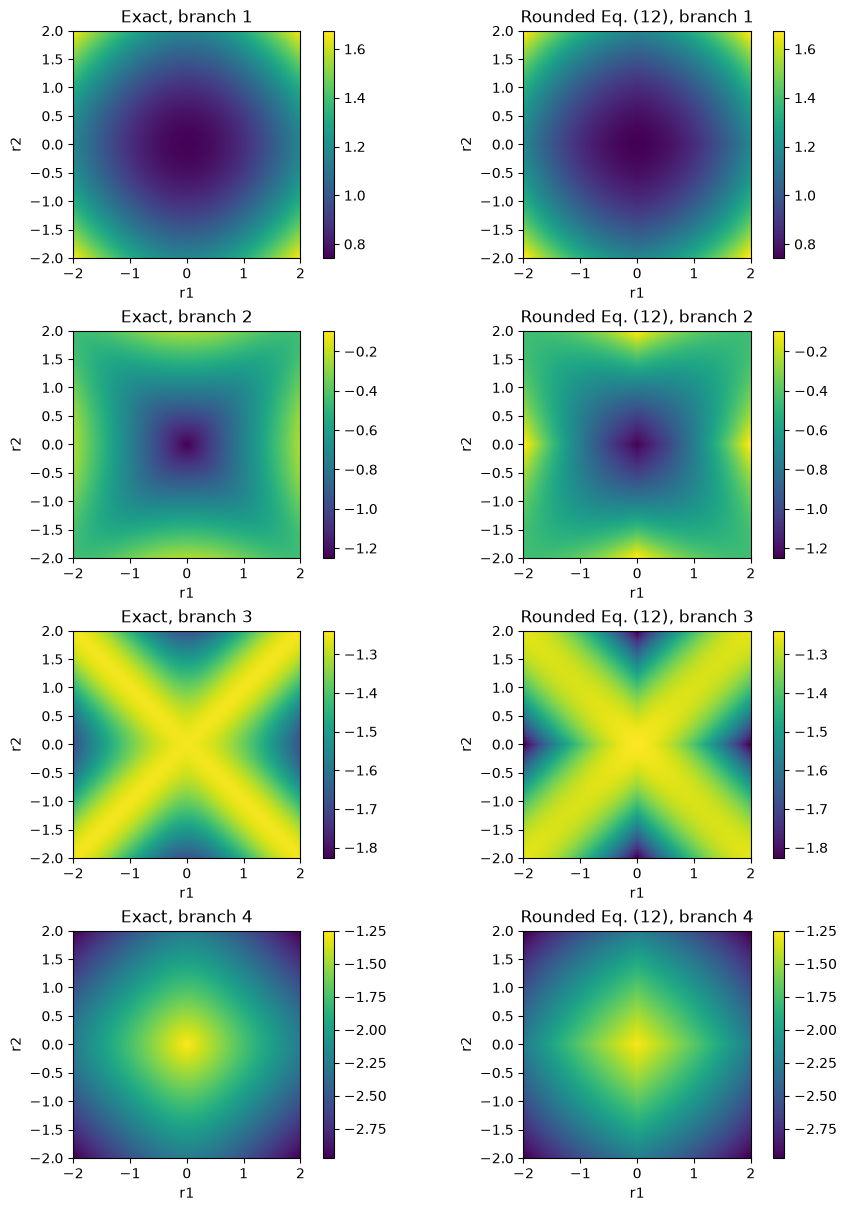

In [5]:
a = np.linspace(-2,2,81); aa,bb=np.meshgrid(a,a)
points=np.column_stack((aa.ravel(),bb.ravel()))
exact=exact_three(points); predicted=published_predictions(abs(points))
fig,axes=plt.subplots(4,2,figsize=(9,12),layout='constrained')
for k in range(4):
    lo=min(exact[:,k].min(),predicted[:,k].min()); hi=max(exact[:,k].max(),predicted[:,k].max())
    for j,(values,label) in enumerate([(exact,'Exact'),(predicted,'Rounded Eq. (12)')]):
        im=axes[k,j].imshow(values[:,k].reshape(aa.shape),origin='lower',extent=(-2,2,-2,2),vmin=lo,vmax=hi)
        axes[k,j].set(title=f'{label}, branch {k+1}',xlabel='r1',ylabel='r2')
        fig.colorbar(im,ax=axes[k,j])
plt.show()

## Train and export

From the repository root:
```bash
python -m experiments.paper --config configs/paper/three_site.json
python -m experiments.paper --config configs/paper/three_site.json --train
```
The first exports these numerical comparisons and figures. The second trains `(2,16,4)` for 1000 epochs and writes a fresh checkpoint, history, full-precision formulas and processed formulas. The original 1.79e-2 neural error cannot be reconstructed without its checkpoint. See [the result map](../../../../docs/reproducing_the_paper.md) for exact scope and [04](04_training_walkthrough.ipynb) for the full training walkthrough.

## Completed full ASN rerun

The following model was trained from scratch for all **1000 epochs on 100,000 samples**, with model and split seed 42. It is separate from the rounded published formulas above. The stored checkpoint is reloaded and its symbolic evaluation is checked against neural predictions. The original CUDA initialization seed was not recorded, so a CPU rerun need not produce identical coefficients.

,rmse,max_abs_error
"Full rerun, complete sample",0.01776,0.15065
"Full rerun, validation",0.017835,0.149191
"Processed rerun formulas, validation",0.017947,0.150495
"Full rerun, independent grid",0.018435,0.154659


Paper complete-sample RMSE: 0.0179
Rerun complete-sample RMSE: 0.017759573624732343
Activation support sizes: [[1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]


,branch,rerun_processed_formula
0,1,0.094*x_0**2 + 0.023*x_0*x_1 + 0.022*x_0 + 0.0...
1,2,0.103*x_0**2 - 0.372*x_0*x_1 + 0.361*x_0 + 0.1...
2,3,-0.132*x_0**2 + 0.287*x_0*x_1 - 0.027*x_0 - 0....
3,4,-0.062*x_0**2 + 0.054*x_0*x_1 - 0.355*x_0 - 0....


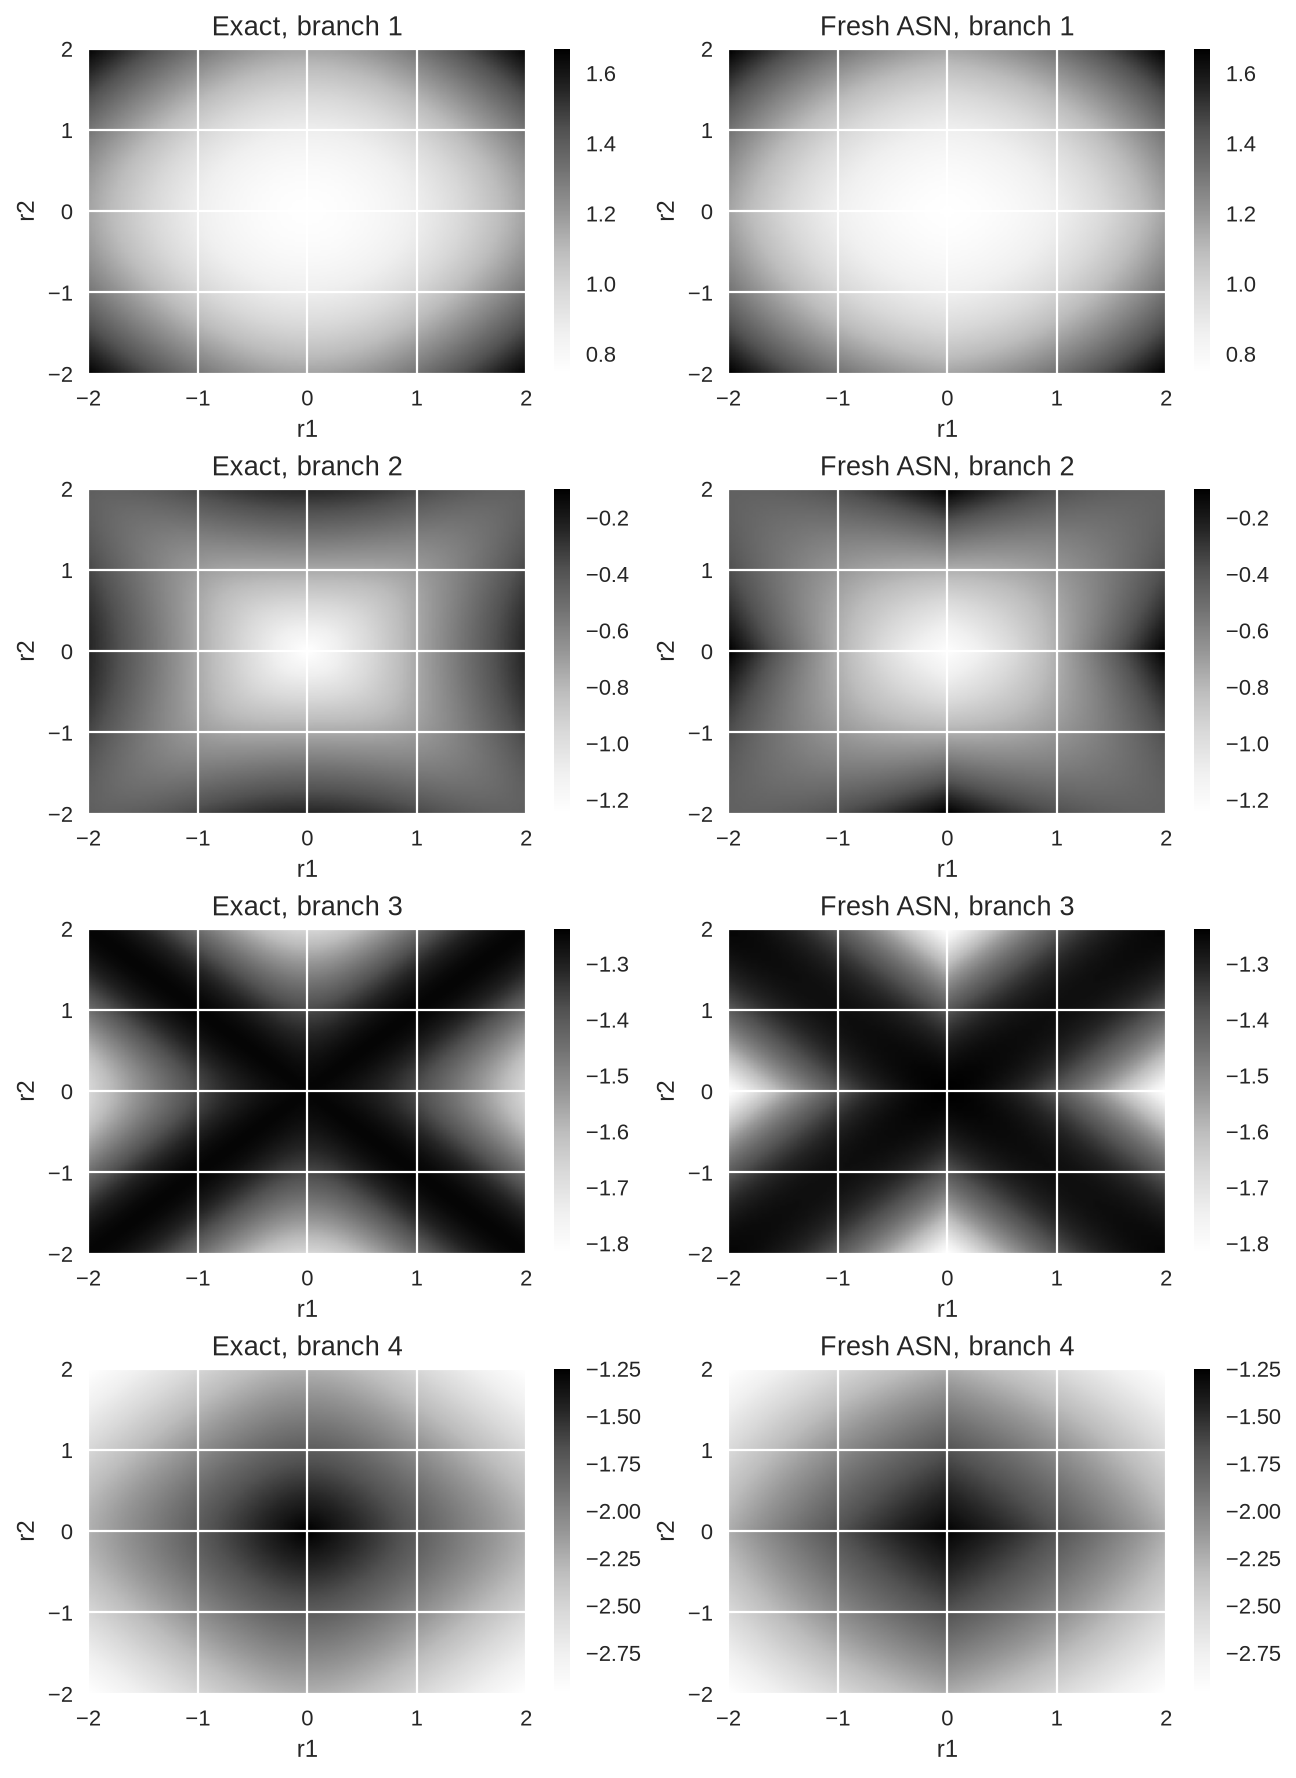

In [6]:
from experiments.reproduction import paper_run_root, load_run
from IPython.display import Image, display
folder=paper_run_root()/'three_site'
trained=load_run(folder)
display(pd.DataFrame({
    'Full rerun, complete sample':trained['all_samples_neural'],
    'Full rerun, validation':trained['validation_neural'],
    'Processed rerun formulas, validation':trained['validation_processed'],
    'Full rerun, independent grid':trained['grid_neural'],
}).T[['rmse','max_abs_error']])
print('Paper complete-sample RMSE:',.0179)
print('Rerun complete-sample RMSE:',trained['all_samples_neural']['rmse'])
print('Activation support sizes:',trained['support_sizes'])
formulas=json.loads((folder/'learned_formulas.json').read_text())
display(pd.DataFrame({'branch':range(1,5),'rerun_processed_formula':formulas['processed']}))
display(Image(filename=str(folder/'fig04_surfaces.png')))

The paper reports 0.0179; this fresh run gives approximately 0.01776 on the complete sample. The printed coefficient structure is recovered, but the coefficients and error are not identical to the original fit. Run `python -m experiments.paper --config configs/paper/three_site.json --train --output outputs/another_three_site_run` to repeat, then set `NMRKAN_PAPER_RUNS` to a root containing completed runs to inspect them here.